# Heliocot — reproduce the derived diurnal indices (DOA, POI) from the paper's analysis-ready PLA table

**Paper:** *Heliocot: A Field RGB Imaging Approach for Diurnal Canopy Orientation Dynamics in Early-Season Cotton*,
MDPI **Agriculture** 16(11):1141 (2026-05-22), DOI [10.3390/agriculture16111141](https://doi.org/10.3390/agriculture16111141).

**Executed scope (partial demonstration):** the paper's own derived-index step (author README **Step 5**):
the author's pinned script `scripts/compute_doa_poi.py` is downloaded **verbatim** from the tagged code release
[`jeolex/heliocot` @ `6b73e1cd`](https://github.com/jeolex/heliocot) (v1.0.5, MIT; git blob sha1 verified) and run on the
paper's analysis-ready table `helio_E_C112_NORM.xlsx` (sheet `wide_by_time`) from the author's Zenodo dataset record
[18243285 v1.0.0](https://zenodo.org/records/18243285) (CC-BY-4.0).

- **DOA** (Daily Orientation Amplitude) = max−min of the 5-point row-normalized `leaf_px_std_1..5` series.
- **POI** (Peak Orientation Index) = `y3 − 0.5·(y1 + y5)` on the 3-point normalized series (t1, t3, t5).

**Not executed / out of scope:** YOLOv8m-seg training or inference, marker-based ROI + C112 post-processing,
reference-area standardization (Steps 0–4), mixed-model/EMM time effects, destructive validation, and genotype
associations. One table is not a verification of the paper's dataset-level results.

**実行する範囲（部分的な再現）:** 論文の導出指標ステップ（著者READMEのStep 5）のみを再現します。著者らのピン留めされた
スクリプトを改変せずに実行し、Zenodoデータセット内の解析済み表 `helio_E_C112_NORM.xlsx`（シート `wide_by_time`）から
DOA（日内方位振幅）と POI（ピーク方位指数）を計算します。YOLO学習・推論、PLA標準化、EMM、遺伝型解析は対象外です。

## Runtime selection

**Select Runtime → Change runtime type → CPU** (the standard CPU runtime is sufficient and recommended:
this step is pure pandas/numpy table computation; no GPU code path exists in the selected scope).
Expected: ≈2.5 GB download (the paper-linked dataset is a multi-part 7z archive; it cannot be partially fetched),
then seconds of computation. End-to-end ≈ 10–20 minutes. Then **Runtime → Run all**.

**ランタイム:** CPU を選択してください（この範囲は表計算のみでGPUは不要）。約2.5 GBのダウンロード後、
計算自体は数秒です。全体の目安は10〜20分です。その後「ランタイム → すべて実行」。

In [ ]:
import os, platform, sys

print("Python:", sys.version)
print("Platform:", platform.platform())
print("CPU count:", os.cpu_count())
import numpy, pandas  # pinned author script requires numpy + pandas

print("numpy:", numpy.__version__, "| pandas:", pandas.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
CPU count: 2


numpy: 2.1.3 | pandas: 2.2.3


### Dependencies

The pinned author script needs `numpy`, `pandas`, and writes Excel via `openpyxl`.
The multi-part Zenodo archive is handled with the `7z` CLI (`p7zip-full`), installed here if missing.

**依存関係:** 著者スクリプトには numpy/pandas/openpyxl が必要です。分割済み7zアーカイブの展開のため
`p7zip-full`（7z CLI）もここで導入します。

In [ ]:
import shutil, subprocess, sys


def run(cmd: list[str]) -> None:
    print("$", " ".join(cmd), flush=True)
    subprocess.run(cmd, check=True)


run([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])
if shutil.which("7z") is None:
    run(["apt-get", "-qq", "update"])
    run(["apt-get", "-qq", "install", "-y", "p7zip-full"])
assert shutil.which("7z") is not None, "7z CLI unavailable"
print("openpyxl OK; 7z at", shutil.which("7z"))

$ /usr/bin/python3 -m pip install -q openpyxl


openpyxl OK; 7z at /usr/bin/7z


### Download the author's pinned script (Step 5)

Fetches `scripts/compute_doa_poi.py` and the MIT `LICENSE` from the tagged release commit `6b73e1cd` (= v1.0.5,
the snapshot archived on Zenodo as record 18253887). The file's **git blob sha1** is asserted against the pinned
value `3d71e9681e82eddddb7a5f750826101e337fc29b`, so any content change fails loudly.

**著者コードの取得:** v1.0.5 タグのコミットから `compute_doa_poi.py` とLICENSEを取得し、
git blob sha1 がピン留め値と一致することを検証します。

In [ ]:
import hashlib
import pathlib
import urllib.request

COMMIT = "6b73e1cd7cd3cbb941d792bbe329645308ffac2d"  # tag v1.0.5, MIT
SCRIPT_BLOB_SHA1 = "3d71e9681e82eddddb7a5f750826101e337fc29b"  # scripts/compute_doa_poi.py

BASE = pathlib.Path("/content/heliocot")
(BASE / "scripts").mkdir(parents=True, exist_ok=True)

raw_url = f"https://raw.githubusercontent.com/jeolex/heliocot/{COMMIT}/scripts/compute_doa_poi.py"
data = urllib.request.urlopen(raw_url, timeout=120).read()
blob = hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()
assert blob == SCRIPT_BLOB_SHA1, f"pinned script mismatch: {blob}"

(BASE / "scripts" / "compute_doa_poi.py").write_bytes(data)
license_bytes = urllib.request.urlopen(
    f"https://raw.githubusercontent.com/jeolex/heliocot/{COMMIT}/LICENSE", timeout=120
).read()
(BASE / "LICENSE").write_bytes(license_bytes)
print(f"compute_doa_poi.py: {len(data)} bytes, git blob sha1 verified: {blob}")
print(f"LICENSE: {len(license_bytes)} bytes (MIT)")

compute_doa_poi.py: 5770 bytes, git blob sha1 verified: 3d71e9681e82eddddb7a5f750826101e337fc29b
LICENSE: 1079 bytes (MIT)


### Download the paper's dataset (multi-part 7z, ≈2.5 GB)

Queries the pinned Zenodo record **18243285** (dataset **v1.0.0**, CC-BY-4.0) and downloads each listed part
through the record's own file links, verifying size and **md5** against the record metadata. This archive is the
only paper-linked source of `helio_E_C112_NORM.xlsx`; a multi-part 7z cannot be partially fetched, which is why
the full ≈2.5 GB download is required (above the 2 GiB soft target — disclosed).

**データセットのダウンロード:** Zenodoレコード18243285（v1.0.0, CC-BY-4.0）から3分割の7z（計約2.5 GB）を
レコード記載のサイズ・md5検証つきで取得します。分割アーカイブは部分取得できないため全文ダウンロードが必要です。

In [ ]:
import hashlib
import json
import pathlib

import requests

RECORD = "18243285"  # pinned version record: Heliocot dataset v1.0.0 (CC-BY-4.0)
DATADIR = pathlib.Path("/content/heliocot_dataset")
DATADIR.mkdir(parents=True, exist_ok=True)

rec = json.loads(requests.get(f"https://zenodo.org/api/records/{RECORD}", timeout=120).text)
assert rec["metadata"]["version"] == "v1.0.0", rec["metadata"].get("version")
expected = {f["key"]: (f["size"], f["checksum"].removeprefix("md5:")) for f in rec["files"]}
assert set(expected) == {
    "heliocot_dataset.7z.001", "heliocot_dataset.7z.002", "heliocot_dataset.7z.003"
}, sorted(expected)


def file_md5(path: pathlib.Path, chunk: int = 1 << 20) -> str:
    h = hashlib.md5()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


for f in sorted(rec["files"], key=lambda f: f["key"]):
    key, size, md5 = f["key"], f["size"], f["checksum"].removeprefix("md5:")
    dest = DATADIR / key
    if dest.exists() and dest.stat().st_size == size:
        print(f"{key}: already present ({size} bytes)")
    else:
        print(f"{key}: downloading {size / 1e6:.0f} MB ...", flush=True)
        with requests.get(f["links"]["self"], stream=True, timeout=600) as r:
            r.raise_for_status()
            done = 0
            with open(dest, "wb") as out:
                for chunk in r.iter_content(chunk_size=8 << 20):
                    out.write(chunk)
                    done += len(chunk)
                    if (done // (200 << 20)) != ((done - len(chunk)) // (200 << 20)):
                        print(f"  {done / 1e9:.2f} GB", flush=True)
    assert dest.stat().st_size == size, (key, dest.stat().st_size, size)
    digest = file_md5(dest)
    assert digest == md5, (key, digest, md5)
    print(f"{key}: size + md5 verified ({digest})")

first = DATADIR / "heliocot_dataset.7z.001"
with open(first, "rb") as fh:
    assert fh.read(6) == b"7z\xbc\xaf\x27\x1c", "not a 7z signature"
print("All parts verified.")

heliocot_dataset.7z.001: downloading 996 MB ...


  0.21 GB


  0.42 GB


  0.63 GB


  0.84 GB


...

  0.84 GB


heliocot_dataset.7z.002: size + md5 verified (ebce1ecae04f1c87b17e2f77768bbd01)
heliocot_dataset.7z.003: downloading 553 MB ...


  0.21 GB


  0.42 GB


heliocot_dataset.7z.003: size + md5 verified (2bc5e2e8bc62c78fa90747c3bde6f0d6)
All parts verified.


### List the archive and locate the analysis-ready table

`7z l -slt` reads only the archive headers. We search the member list for `helio_E_C112_NORM.xlsx` (the Step 5
input) and, if present, also `helio_E_C112_DOA_POI.xlsx` (an author-provided reference output used later for
cross-checking). If the required member is absent, the run stops with an explicit error instead of guessing.

**アーカイブ内の探索:** ヘッダのみ読んで `helio_E_C112_NORM.xlsx`（必須）と
`helio_E_C112_DOA_POI.xlsx`（あれば検証用参照）の場所を特定します。無い場合は明示的に停止します。

In [ ]:
import pathlib
import subprocess

part1 = DATADIR / "heliocot_dataset.7z.001"
listing = subprocess.run(["7z", "l", "-slt", str(part1)], capture_output=True, text=True, check=True).stdout
paths = [line[len("Path = "):].strip() for line in listing.splitlines() if line.startswith("Path = ")]
print(f"{len(paths)} members listed")

norm_members = [p for p in paths if pathlib.PurePosixPath(p).name == "helio_E_C112_NORM.xlsx"]
ref_members = [p for p in paths if pathlib.PurePosixPath(p).name == "helio_E_C112_DOA_POI.xlsx"]
assert len(norm_members) == 1, f"expected exactly one helio_E_C112_NORM.xlsx, found {norm_members}"
print("Step 5 input:", norm_members[0])
print("Author reference DOA/POI output:", ref_members if ref_members else "not present in archive")

1020 members listed
Step 5 input: heliocot_dataset/workflow/outputs/helio_E_C112_NORM.xlsx
Author reference DOA/POI output: ['heliocot_dataset/workflow/outputs/helio_E_C112_DOA_POI.xlsx']


### Extract only the needed members

Extracts just the located `.xlsx` member(s) — not the ≈2.5 GB of images — into `/content/heliocot/workflow/outputs/`,
and reports the extracted size.

**抽出:** 画像本体は展開せず、特定した xlsx のみを `/content` 以下に抽出します。

In [ ]:
import subprocess

OUTDIR = pathlib.Path("/content/heliocot/workflow/outputs")
OUTDIR.mkdir(parents=True, exist_ok=True)

to_extract = norm_members + ref_members
subprocess.run(["7z", "x", "-y", f"-o{OUTDIR}", str(part1), *to_extract], check=True)
extracted = sorted(OUTDIR.rglob("helio_E_C112_*.xlsx"))
assert extracted, "extraction produced no files"
xlsx = next(p for p in extracted if p.name == "helio_E_C112_NORM.xlsx")
for p in extracted:
    print(p, p.stat().st_size, "bytes")

/content/heliocot/workflow/outputs/heliocot_dataset/workflow/outputs/helio_E_C112_DOA_POI.xlsx 17150 bytes
/content/heliocot/workflow/outputs/heliocot_dataset/workflow/outputs/helio_E_C112_NORM.xlsx 48513 bytes


### Inspect the input table (`wide_by_time`)

Reads the sheet the author script consumes and asserts the required `leaf_px_std_1..5` columns (the same check the
author script performs). Shows the shape, column names, key columns, and the first rows — the actual observed
schema, with no assumptions hard-coded.

**入力表の確認:** 著者スクリプトと同じ必須列チェックを行い、実際のスキーマと先頭行を表示します。

In [ ]:
import pandas as pd

REQUIRED = [f"leaf_px_std_{i}" for i in [1, 2, 3, 4, 5]]

sheet = pd.read_excel(xlsx, sheet_name="wide_by_time")
missing = [c for c in REQUIRED if c not in sheet.columns]
assert not missing, f"Missing required columns in wide_by_time: {missing}"

print("wide_by_time shape:", sheet.shape)
print("columns:", list(sheet.columns))
key_cols = [c for c in ["parsel_no", "cultivar", "rep", "plant_no"] if c in sheet.columns]
display(sheet[key_cols + REQUIRED].head(8))

wide_by_time shape: (30, 9)
columns: ['parsel_no', 'cultivar', 'rep', 'plant_no', 'leaf_px_std_1', 'leaf_px_std_2', 'leaf_px_std_3', 'leaf_px_std_4', 'leaf_px_std_5']


,parsel_no,cultivar,rep,plant_no,leaf_px_std_1,leaf_px_std_2,leaf_px_std_3,leaf_px_std_4,leaf_px_std_5
0,1,1,1,3,548795.093006,580521.247327,608067.303703,554753.969781,5.360592e+05
1,2,1,2,2,274413.635150,289139.965163,318745.750632,291572.118328,2.677140e+05
2,3,1,3,2,312546.936299,339709.298751,382424.657677,401549.485530,3.656294e+05
3,4,2,1,2,424103.916150,472284.040034,467618.868576,463009.067438,4.152350e+05
4,5,2,2,2,315642.398834,331749.017231,371386.738424,311180.007525,2.775131e+05
5,6,2,3,2,572826.064838,591538.676342,612098.027614,596196.943498,5.376534e+05
6,7,3,1,2,906744.918793,910021.125697,981748.636728,962341.952243,1.026546e+06
7,8,3,2,2,295251.497646,301044.351083,333119.126182,323844.344964,2.809192e+05


### Input preview — diurnal standardized PLA series

Plots the 5-point reference-standardized PLA series (`leaf_px_std_1..5`, the input the indices are computed from)
for a sample of rows plus the row-mean curve. X positions are the recorded time-point index T1..T5; the notebook
does not invent clock times. This graph shows **input data**, created for this notebook (not an author figure).

**入力プレビュー:** `wide_by_time` の標準化PLA系列（T1〜T5の記録順、時刻は推定しない）を
サンプル行と平均曲線で可視化します（本ノートブックによる作図）。

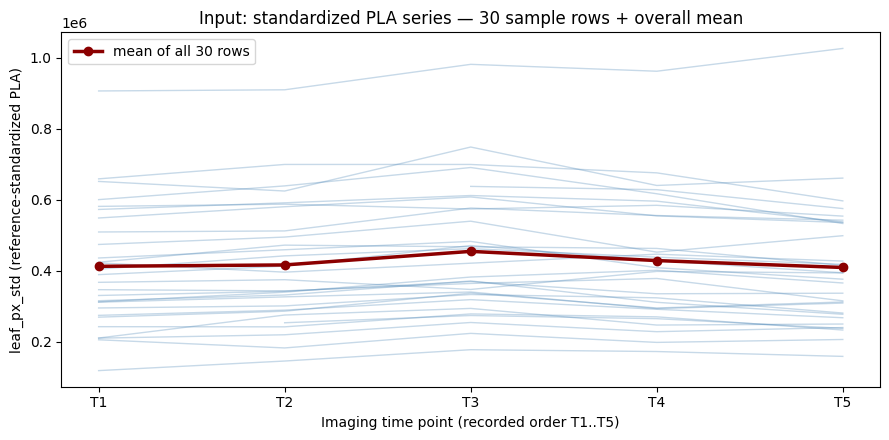

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
n_show = min(30, len(sheet))
for _, row in sheet[REQUIRED].head(n_show).iterrows():
    ax.plot([1, 2, 3, 4, 5], row[REQUIRED].astype(float), color="steelblue", alpha=0.3, lw=1)
mean_curve = sheet[REQUIRED].mean(skipna=True)
ax.plot([1, 2, 3, 4, 5], mean_curve, color="darkred", lw=2.5, marker="o",
        label=f"mean of all {len(sheet)} rows")
ax.set_xticks([1, 2, 3, 4, 5], [f"T{i}" for i in [1, 2, 3, 4, 5]])
ax.set_xlabel("Imaging time point (recorded order T1..T5)")
ax.set_ylabel("leaf_px_std (reference-standardized PLA)")
ax.set_title(f"Input: standardized PLA series — {n_show} sample rows + overall mean")
ax.legend()
fig.tight_layout()
plt.show()

### Run the author's Step 5 script (default parameters)

Executes the downloaded, sha1-verified `compute_doa_poi.py` with the recommended explicit arguments
(`--sheet wide_by_time --norm5 mean --norm3 mean`) — i.e. the author's own implementation and defaults, not a
re-implementation. Its stdout is streamed and a non-zero exit fails the cell.

**著者スクリプトの実行:** 改変なしの `compute_doa_poi.py` を推奨引数で実行します（失敗時はエラーで停止）。

In [ ]:
import subprocess
import sys

out_xlsx = "/content/heliocot/workflow/outputs/helio_E_C112_DOA_POI.xlsx"
cmd = [
    sys.executable, "/content/heliocot/scripts/compute_doa_poi.py",
    "--in-xlsx", str(xlsx),
    "--sheet", "wide_by_time",
    "--out-xlsx", out_xlsx,
    "--norm5", "mean",
    "--norm3", "mean",
]
print("$", " ".join(cmd), flush=True)
result = subprocess.run(cmd)
assert result.returncode == 0, f"compute_doa_poi.py failed: exit {result.returncode}" 

$ /usr/bin/python3 /content/heliocot/scripts/compute_doa_poi.py --in-xlsx /content/heliocot/workflow/outputs/heliocot_dataset/workflow/outputs/helio_E_C112_NORM.xlsx --sheet wide_by_time --out-xlsx /content/heliocot/workflow/outputs/helio_E_C112_DOA_POI.xlsx --norm5 mean --norm3 mean


### Inspect the produced indices

Loads the workbook the script wrote, lists its sheets, and displays DOA/POI summary statistics, the plot-level
table, and the cultivar mean ± SE table (as produced by the author's code). A CSV copy of the per-row indices is
saved next to it for easy export.

**結果の確認:** スクリプトが書き出したワークブックのシート一覧、DOA/POI統計、プロット単位・品種単位の
集計表を表示し、CSVも保存します。

In [ ]:
import pandas as pd

sheets = pd.ExcelFile(out_xlsx).sheet_names
print("sheets:", sheets)

res = pd.read_excel(out_xlsx, sheet_name="wide_by_time_plus_DOA_POI")
print("rows:", len(res))
display(res[["DOA", "POI"]].describe())

for name in ["plot_level_DOA_POI", "cultivar_mean_SE"]:
    if name in sheets:
        table = pd.read_excel(out_xlsx, sheet_name=name)
        print(f"--- {name} ({len(table)} rows)")
        display(table.head(12))

res.to_csv("/content/heliocot_DOA_POI.csv", index=False)
print("CSV written: /content/heliocot_DOA_POI.csv")

sheets: ['wide_by_time_plus_DOA_POI', 'plot_level_DOA_POI', 'cultivar_mean_SE', 'definitions']
rows: 30


,DOA,POI
count,30.000000,29.000000
mean,0.179202,0.120323
std,0.069998,0.075123
min,0.058384,-0.090038
25%,0.127452,0.097166
50%,0.173561,0.116320
75%,0.200230,0.161700
max,0.380899,0.256219


--- plot_level_DOA_POI (30 rows)


,parsel_no,cultivar,rep,n_plants,DOA,POI
0,1,1,1,1,0.127304,0.116320
1,2,1,2,1,0.176999,0.166164
2,3,1,3,1,0.246974,0.122581
3,4,2,1,1,0.127214,0.110063
4,5,2,2,1,0.291992,0.232677
5,6,2,3,1,0.127898,0.099023
6,7,3,1,1,0.125122,0.015543
7,8,3,2,1,0.170123,0.148579
8,9,3,3,1,0.135098,-0.090038
9,10,4,1,1,0.256035,0.204070


--- cultivar_mean_SE (10 rows)


,cultivar,DOA_n_plot,DOA_mean,DOA_se,POI_n_plot,POI_mean,POI_se
0,1,3,0.183759,0.034711,3,0.135021,0.015676
1,2,3,0.182368,0.054812,3,0.147255,0.042830
2,3,3,0.143448,0.013645,3,0.024695,0.069035
3,4,3,0.140312,0.059507,3,0.107219,0.055687
4,5,3,0.143771,0.021324,3,0.073348,0.042300
5,6,3,0.150899,0.014266,2,0.140239,0.021462
6,7,3,0.274026,0.081359,3,0.204581,0.050247
7,8,3,0.186381,0.007743,3,0.095289,0.006522
8,9,3,0.195112,0.028342,3,0.131756,0.024447
9,10,3,0.191945,0.020897,3,0.150467,0.023119


CSV written: /content/heliocot_DOA_POI.csv


### Cross-check against the author's archived reference output (if present)

If the dataset archive also contains the authors' own `helio_E_C112_DOA_POI.xlsx`, it is extracted and compared
column-by-column with this notebook's result (per-element difference on DOA/POI). This is a validation against
**author reference values**, not a claim beyond the single table.

**検証:** アーカイブに著者の参照出力 `helio_E_C112_DOA_POI.xlsx` があれば抽出し、
本ノートブックの DOA/POI と要素ごとに比較します。

In [ ]:
import numpy as np
import pandas as pd

if ref_members:
    REFDIR = pathlib.Path("/content/heliocot/author_reference")
    REFDIR.mkdir(parents=True, exist_ok=True)
    subprocess.run(["7z", "x", "-y", f"-o{REFDIR}", str(part1), *ref_members], check=True)
    ref_xlsx = next(REFDIR.rglob("helio_E_C112_DOA_POI.xlsx"))
    ref = pd.read_excel(ref_xlsx, sheet_name="wide_by_time_plus_DOA_POI")
    comparable = "DOA" in ref.columns and "POI" in ref.columns and len(ref) == len(res)
    if not comparable:
        print("Reference sheet schema differs from this run's output; reported, not compared.")
    else:
        for col in ["DOA", "POI"]:
            a = res[col].to_numpy(dtype=float)
            b = ref[col].to_numpy(dtype=float)
            finite = np.isfinite(a) & np.isfinite(b)
            max_abs = float(np.max(np.abs(a[finite] - b[finite]))) if finite.any() else 0.0
            agree = np.array_equal(np.isfinite(a), np.isfinite(b)) and max_abs <= 1e-9
            print(f"{col}: rows={len(b)}, max|ours−reference| over finite entries = {max_abs:.3e}, match={agree}")
else:
    print("No author reference output in the archive; skipping cross-check.")

DOA: rows=30, max|ours−reference| over finite entries = 0.000e+00, match=True
POI: rows=30, max|ours−reference| over finite entries = 0.000e+00, match=True


### Result graphs — DOA and POI distributions

Plots the distribution of the two indices over all rows of the selected table. These are additional visualizations
created for this notebook from the actual computed values — **not** author figures or published results.

**結果のグラフ:** 計算された DOA/POI の分布を表示します（著者図ではなく本ノートブックによる追加可視化）。

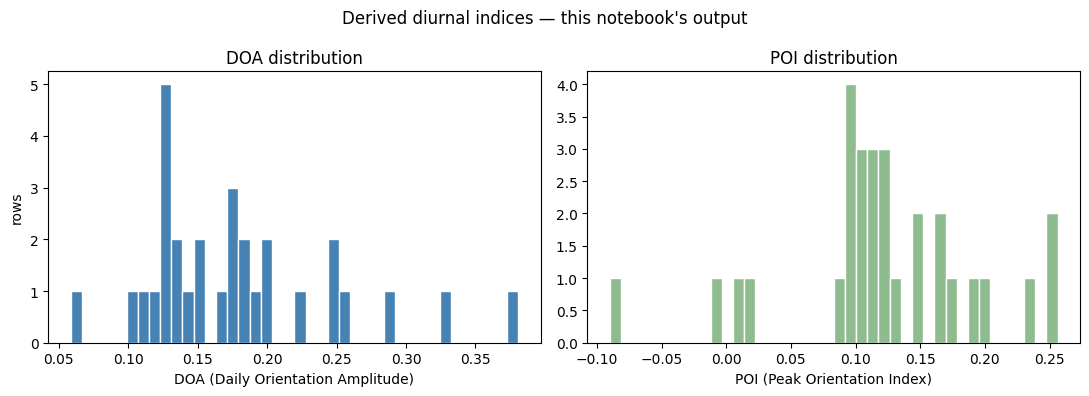

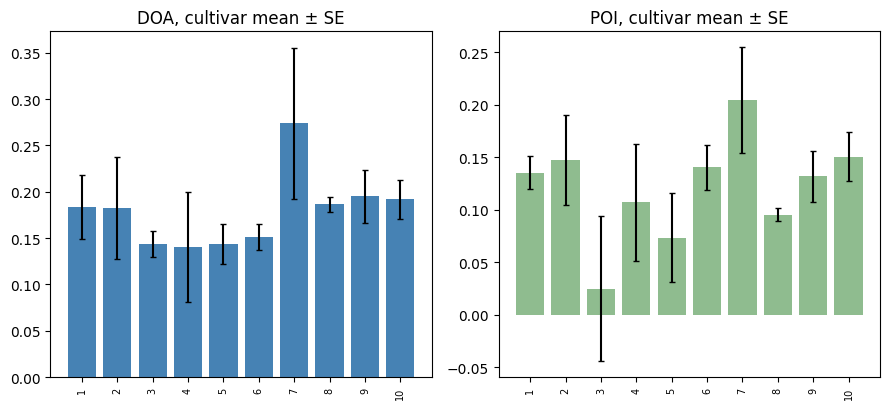

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(res["DOA"].dropna(), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("DOA distribution")
axes[0].set_xlabel("DOA (Daily Orientation Amplitude)")
axes[0].set_ylabel("rows")
axes[1].hist(res["POI"].dropna(), bins=40, color="darkseagreen", edgecolor="white")
axes[1].set_title("POI distribution")
axes[1].set_xlabel("POI (Peak Orientation Index)")
fig.suptitle("Derived diurnal indices — this notebook's output")
fig.tight_layout()
plt.show()

if "cultivar_mean_SE" in sheets:
    cult = pd.read_excel(out_xlsx, sheet_name="cultivar_mean_SE")
    if 0 < len(cult) <= 40:
        fig2, axes2 = plt.subplots(1, 2, figsize=(max(8, 0.5 * len(cult) + 4), 4.2), sharey=False)
        x = range(len(cult))
        axes2[0].bar(x, cult["DOA_mean"], yerr=cult["DOA_se"], color="steelblue", capsize=2)
        axes2[0].set_title("DOA, cultivar mean ± SE")
        axes2[1].bar(x, cult["POI_mean"], yerr=cult["POI_se"], color="darkseagreen", capsize=2)
        axes2[1].set_title("POI, cultivar mean ± SE")
        for ax_i in axes2:
            ax_i.set_xticks(list(x), cult["cultivar"].astype(str), rotation=90, fontsize=7)
        fig2.tight_layout()
        plt.show()
    else:
        print(f"cultivar_mean_SE has {len(cult)} rows; table shown above instead of a bar chart.")

## Interpretation and validation record

- **Executed:** the author's pinned `compute_doa_poi.py` (v1.0.5, git blob sha1 verified) on the paper's archived
  `helio_E_C112_NORM.xlsx` (sheet `wide_by_time`), producing `helio_E_C112_DOA_POI.xlsx` with per-row DOA/POI,
  plot-level and cultivar summaries, and the author's definitions sheet — the paper's Step 5 output.
- **Validated in this run:** pinned script hash, Zenodo record version + per-part size/md5, required input schema,
  and (when present) element-wise agreement with the authors' archived reference output printed above.
- **Interpretation:** DOA quantifies within-day amplitude of the standardized projected leaf area and POI the
  midday peak asymmetry; both are computed exactly as defined by the authors. Per the paper's abstract, these
  metrics revealed a midday maximum in canopy projection; this notebook computes them on the selected table but
  does not re-evaluate dataset-level statistics.
- **Not verified here:** segmentation quality, PLA standardization, EMM time effects, destructive validation and
  genotype associations (paper Steps 0–4 and later analyses).
- **Provenance:** code MIT (© authors, `jeolex/heliocot`); dataset CC-BY-4.0 (Zenodo 18243285 v1.0.0);
  paper © MDPI Agriculture 16(11):1141. Citations: see the links at the top.

**まとめ:** 論文のStep 5（DOA/POI計算）を著者コードのままで再現しました。ピン留めしたスクリプトのハッシュ、
Zenodoレコードのバージョンと各部品のmd5、入力スキーマ、（あれば）著者参照出力との一致を検証しています。
セグメンテーションやPLA標準化、EMMなどの前段・後段解析は本ノートブックの対象外です。